# Projet Deep Learning II

## Partie 1 - Introduction

Ce projet vise à concevoir un réseau de neurones profonds, un DNN, pour la classification de chiffres manuscrits, en comparant un réseau pré-entraîné avec un réseau initialisé aléatoirement. L’étude analysera l’impact du nombre de données d’apprentissage, du nombre de couches et du nombre de neurones par couche sur les performances du modèle.

## Partie 2 - Importation des Données

Nous utilisons deux bases de données :

- **Binary AlphaDigits** pour tester les algorithmes en apprentissage non supervisé.

- **MNIST** pour l’évaluation finale des performances du DNN.

In [ ]:
# Importations des bibliothèques
import numpy as np
import scipy.io
import os
import gzip
import struct
import matplotlib.pyplot as plt
from tqdm import tqdm

Type de binary_alpha_images : <class 'numpy.ndarray'>
Taille de binary_alpha_images : 36 (Nombre de classes) 

Type de binary_alpha_labels : <class 'numpy.ndarray'>
Taille de binary_alpha_labels : 36 (Correspond aux classes)

Type d'une image : <class 'numpy.ndarray'>
Dimensions d'une image : (20, 16)



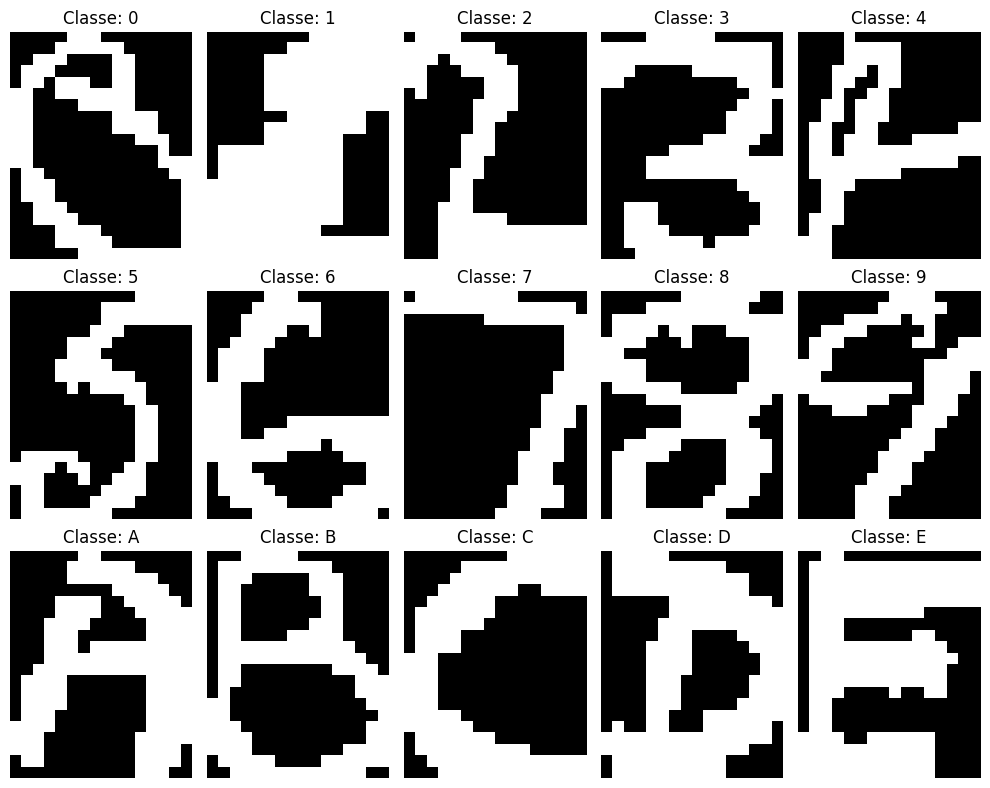

In [ ]:
# Chargement de Binary AlphaDigits
binary_alpha_data = scipy.io.loadmat("./binaryalphadigs.mat")
binary_alpha_images = binary_alpha_data["dat"]
binary_alpha_labels = binary_alpha_data["classlabels"][0]

print(f"Type de binary_alpha_images : {type(binary_alpha_images)}")
print(f"Taille de binary_alpha_images : {len(binary_alpha_images)} (Nombre de classes) \n")

print(f"Type de binary_alpha_labels : {type(binary_alpha_labels)}")
print(f"Taille de binary_alpha_labels : {len(binary_alpha_labels)} (Correspond aux classes)\n")

sample_images = binary_alpha_images[0]  # Liste d'images de la classe 0
if len(sample_images) > 0:
    sample_image = sample_images[0]  # Première image de la classe O
    print(f"Type d'une image : {type(sample_image)}")
    print(f"Dimensions d'une image : {sample_image.shape}\n")

# Affichage de quelques images
fig, axes = plt.subplots(3, 5, figsize=(10, 8))
axes = axes.ravel()
for i in range(min(len(binary_alpha_images), 15)):  # On affiche maximum 15 classes
    img_list = binary_alpha_images[i]
    if len(img_list) > 0:
        axes[i].imshow(img_list[0] , cmap="gray") # Première image de la classe
        axes[i].set_title(f"Classe: {binary_alpha_labels[i].item()}")
        axes[i].axis("off")
plt.tight_layout()
plt.show()

Type de train_images : <class 'numpy.ndarray'>, Dimensions : (60000, 28, 28)
Type de train_labels : <class 'numpy.ndarray'>, Taille : 60000

Type de test_images : <class 'numpy.ndarray'>, Dimensions : (10000, 28, 28)
Type de test_labels : <class 'numpy.ndarray'>, Taille : 10000



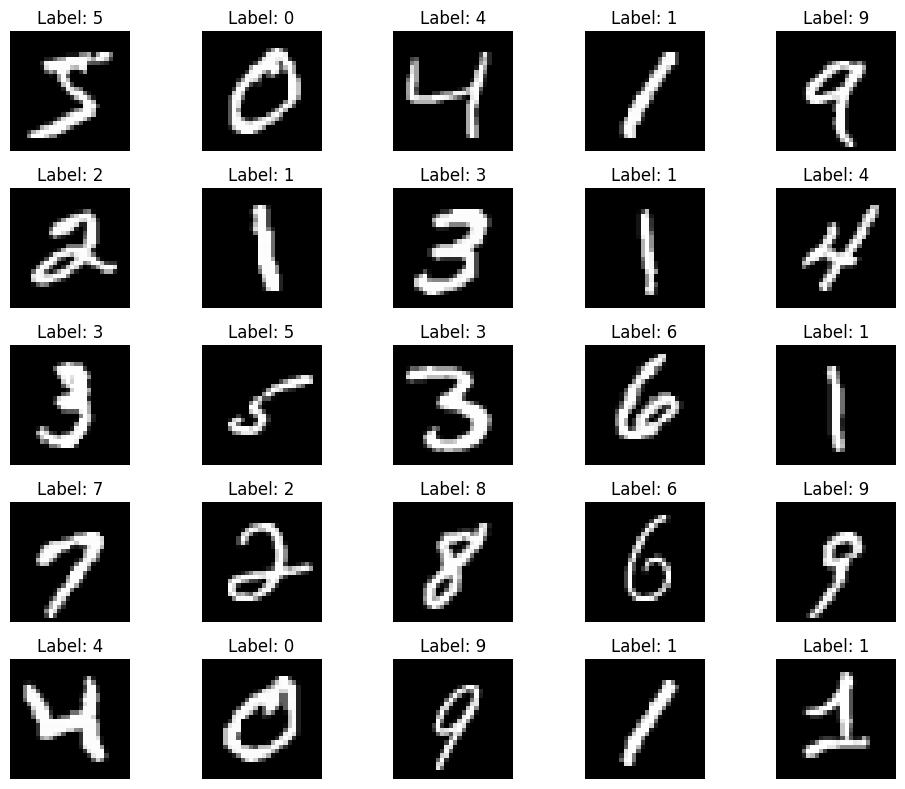

In [ ]:
# Chargement des fichiers MNIST
mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def load_mnist_images(filepath):
    with gzip.open(filepath, 'rb') as f:
        _, num_images, rows, cols = struct.unpack(">IIII", f.read(16))
        images = np.frombuffer(f.read(), dtype=np.uint8).reshape(num_images, rows, cols)
    return images

def load_mnist_labels(filepath):
    with gzip.open(filepath, 'rb') as f:
        _, num_labels = struct.unpack(">II", f.read(8))
        labels = np.frombuffer(f.read(), dtype=np.uint8)
    return labels

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"]))
train_labels = load_mnist_labels(os.path.join(mnist_path, files["train_labels"]))
test_images  = load_mnist_images(os.path.join(mnist_path, files["test_images"]))
test_labels  = load_mnist_labels(os.path.join(mnist_path, files["test_labels"]))

print(f"Type de train_images : {type(train_images)}, Dimensions : {train_images.shape}")
print(f"Type de train_labels : {type(train_labels)}, Taille : {len(train_labels)}\n")

print(f"Type de test_images : {type(test_images)}, Dimensions : {test_images.shape}")
print(f"Type de test_labels : {type(test_labels)}, Taille : {len(test_labels)}\n")

# Affichage de quelques (15) images de MNIST avec leurs labels
fig, axes = plt.subplots(5, 5, figsize=(10, 8))
axes = axes.ravel()
for i in range(25):
    img = train_images[i]
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"Label: {train_labels[i]}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## Partie 3 - Fonctions Élémentaires

Dans cette section, nous implémentons les fonctions de base nécessaires à la construction et à l’entraînement de modèles de réseaux neuronaux : RBM (Restricted Boltzmann Machine), DBN (Deep Belief Network) et DNN (Deep Neural Network). À ce stade, nous définissons uniquement les structures et les opérations essentielles, sans exécuter l’entraînement ou les tests.

Un RBM est une couche de neurones cachés connectée à une couche de neurones visibles. Il est représenté par :

- W = matrice de poids reliant les unités visibles aux unités cachées.
- a = biais des unités visibles.
- b = biais des unités cachées.

Un DBN (Deep Belief Network) est une pile de RBM entraînés successivement, permettant un apprentissage non supervisé en profondeur.

Un DNN (Deep Neural Network) est similaire à un DBN mais inclut une couche de classification supervisée. Il est entraîné par rétropropagation après un pré-entraînement non supervisé.

### 3.1 Construction d'un RBM et test sur Binary AlphaDigits

Nous définissons les fonctions permettant d’implémenter un RBM et de l’entraîner sur un sous-ensemble de caractères de la base Binary AlphaDigits. Ce modèle génératif apprend une représentation latente des données et permet de générer de nouveaux échantillons.

In [ ]:
# Récupère les données sous forme matricielle
def lire_alpha_digit(indices):

    data_list, label_list = [], []
    for idx in indices:
        for img in binary_alpha_images[idx]:

            data_list.append(img.flatten())
            label_list.append(binary_alpha_labels[idx].item())

    return np.array(data_list, dtype=np.float32), np.array(label_list)


# Initialise les poids et les biais d’un RBM
def init_RBM(n_visible, n_hidden):

    rbm = {"W": np.random.normal(0, 0.01, (n_visible, n_hidden)),
           "a": np.zeros(n_visible),
           "b": np.zeros(n_hidden)}
    return rbm


# Calcule la sortie cachée d’un RBM à partir des entrées
def entree_sortie_RBM(rbm, data):

    z = np.dot(data, rbm["W"]) + rbm["b"]
    return 1 / (1 + np.exp(-z))


# Reconstruit l’entrée à partir des unités cachées
def sortie_entree_RBM(rbm, hidden_data):

    z = np.dot(hidden_data, rbm["W"].T) + rbm["a"]
    return 1 / (1 + np.exp(-z))


# Apprend un RBM par l’algorithme Contrastive Divergence-1
def train_RBM(rbm, data, epochs=1000, learning_rate=0.01, batch_size=10, weight_decay=0.0001):

    n_samples = data.shape[0]
    reconstruction_errors = []
    for epoch in range(epochs):

        data = np.copy(data)
        np.random.shuffle(data)
        epoch_error = 0
        for i in range(0, n_samples, batch_size):

            batch = data[i:i+batch_size]

            h_prob = entree_sortie_RBM(rbm, batch)
            h_sample = (h_prob > np.random.rand(*h_prob.shape)).astype(np.float32)

            v_recon_prob = sortie_entree_RBM(rbm, h_sample)
            v_recon_sample = (v_recon_prob > np.random.rand(*v_recon_prob.shape)).astype(np.float32)

            h_recon_prob = entree_sortie_RBM(rbm, v_recon_sample)

            rbm["W"] += learning_rate * ((np.dot(batch.T, h_prob) - np.dot(v_recon_sample.T, h_recon_prob)) / batch_size - weight_decay * rbm["W"])
            rbm["a"] += learning_rate * np.mean(batch - v_recon_sample, axis=0)
            rbm["b"] += learning_rate * np.mean(h_prob - h_recon_prob, axis=0)

            epoch_error += np.mean((batch - v_recon_prob) ** 2)

        reconstruction_errors.append(epoch_error)

        if (epoch+1) % 500 == 0 or epoch==0:
            print(f"Epoch {epoch+1}/{epochs} - Reconstruction Error: {epoch_error:.6f}")

    return rbm, reconstruction_errors


# Génère des images à partir d’un RBM entraîné
def generer_image_RBM(rbm, n_samples=10, n_iter=5000):

    # Initialisation aléatoire avec bruit gaussien
    images = np.random.normal(0, 1, (n_samples, rbm["W"].shape[0]))

    for _ in range(n_iter):
        h_prob = entree_sortie_RBM(rbm, images)
        h_sample = (h_prob > np.random.rand(*h_prob.shape)).astype(np.float32)
        v_prob = sortie_entree_RBM(rbm, h_sample)
        images = (v_prob > np.random.rand(*v_prob.shape)).astype(np.float32)

    images = np.clip(images, 0, 1)

    fig, axes = plt.subplots(1, n_samples, figsize=(n_samples, 2))
    for i in range(n_samples):
        axes[i].imshow(images[i].reshape(20, 16), cmap="gray")
        axes[i].axis("off")
    plt.show()

    return images

### 3.2 Construction d’un DBN et test sur Binary AlphaDigits

Nous implémentons les fonctions nécessaires à la construction et à l’entraînement d’un DBN en empilant plusieurs RBM. L’apprentissage suit une approche couche par couche, où chaque RBM est entraîné indépendamment avant d’être combiné dans un réseau plus profond.

In [ ]:
# Initialise un DBN en créant une liste de RBM successifs
def init_DBN(layer_sizes):

    dbn = []
    for i in range(len(layer_sizes) - 1):
        rbm = init_RBM(layer_sizes[i], layer_sizes[i + 1])
        dbn.append(rbm)

    return dbn


# Entraîne un DBN couche par couche en utilisant un apprentissage non supervisé
def train_DBN(dbn, data, epochs, learning_rate, batch_size):
    layer_input = data
    for i, rbm in enumerate(dbn):
        print(f"\nEntraînement du RBM {i + 1}/{len(dbn)}\n")

        lr = learning_rate / (i + 1)
        rbm, _ = train_RBM(rbm, layer_input, epochs, lr, batch_size)
        dbn[i] = rbm
        layer_input = entree_sortie_RBM(rbm, layer_input)

    return dbn


# Génère des échantillons à partir d'un DBN en effectuant une chaîne de Gibbs
def generer_image_DBN(dbn, binary_alpha_images, caracteres_selectionnes, num_iterations=10000, num_images=10):

    # Sélection des images du dataset, on part d'échantillons réels
    data_list = []
    for idx in caracteres_selectionnes:
        for img in binary_alpha_images[idx]:
            data_list.append(img.flatten())
    data_list = np.array(data_list, dtype=np.float32)

    images_generees = data_list[np.random.choice(len(data_list), num_images, replace=False)]

    for _ in range(num_iterations):

        images_generees += np.random.normal(0, 0.05, images_generees.shape)

        for rbm in dbn:# Propagation avant
            images_generees = entree_sortie_RBM(rbm, images_generees)

        for rbm in reversed(dbn): # Propagation arrière
            images_generees = sortie_entree_RBM(rbm, images_generees)

    images_generees = np.clip(images_generees, 0, 1)

    # Affichage des images générées
    fig, axes = plt.subplots(1, num_images, figsize=(num_images * 2, 2))
    for i in range(num_images):
        axes[i].imshow(images_generees[i].reshape(20, 16), cmap="gray")
        axes[i].axis("off")
    plt.show()

    return images_generees

### 3.3 Construction d’un DNN et test sur MNIST

Nous construisons les fonctions essentielles à l’apprentissage d’un DNN sur MNIST. Contrairement au DBN, le DNN ajoute une couche de classification en sortie et est affiné par rétropropagation. Nous mettons en place les outils pour son initialisation, son pré-entraînement et son entraînement supervisé.

In [ ]:
# Initialisation du DNN
def init_DNN(layer_sizes):
    dbn = init_DBN(layer_sizes[:-1])
    W = np.random.randn(layer_sizes[-2], layer_sizes[-1]) * 0.01
    b = np.zeros(layer_sizes[-1])
    dbn.append({"W": W, "b": b})
    return dbn

def calcul_softmax(W, b, data):
    z = np.dot(data, W) + b
    exp_z = np.exp(z - np.max(z, axis=1, keepdims=True))
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

# Fonction pour pré-entraîner le DNN
def pretrain_DNN(layer_sizes, train_data, rbm_epochs=25, learning_rate=0.1, batch_size=10):
    dbn = init_DBN(layer_sizes[:-1])
    dbn = train_DBN(dbn, train_data, rbm_epochs, learning_rate, batch_size)
    pretrained_dnn = [{"W": rbm["W"], "b": rbm["b"]} for rbm in dbn]
    W = np.random.randn(layer_sizes[-2], layer_sizes[-1]) * 0.01
    b = np.zeros(layer_sizes[-1])
    pretrained_dnn.append({"W": W, "b": b})
    return pretrained_dnn

# Fonction de propagation avant pour un réseau DNN
def entree_sortie_reseau(dnn, data):
    activations = [data]
    for rbm in dnn[:-1]:
        data = entree_sortie_RBM(rbm, data)
        activations.append(data)
    output = calcul_softmax(dnn[-1]["W"], dnn[-1]["b"], data)
    activations.append(output)
    return activations, output

# Fonction de rétropropagation pour le DNN
def retropropagation(dnn, data, labels, epochs, learning_rate, batch_size):
    for epoch in range(epochs):
        indices = np.arange(len(data))
        np.random.shuffle(indices)
        data, labels = data[indices], labels[indices]
        total_loss = 0

        for i in range(0, len(data), batch_size):
            batch_data = data[i:i+batch_size]
            batch_labels = labels[i:i+batch_size]
            activations, probs = entree_sortie_reseau(dnn, batch_data)

            error = probs - batch_labels
            grad = error / batch_size

            dnn[-1]["W"] -= learning_rate * np.dot(activations[-2].T, grad)
            dnn[-1]["b"] -= learning_rate * np.sum(grad, axis=0)

            for l in range(len(dnn)-2, -1, -1):
                grad = np.dot(grad, dnn[l+1]["W"].T) * activations[l+1] * (1 - activations[l+1])
                dnn[l]["W"] -= learning_rate * np.dot(activations[l].T, grad)
                dnn[l]["b"] -= learning_rate * np.sum(grad, axis=0)

            batch_loss = -np.mean(np.sum(batch_labels * np.log(probs + 1e-10), axis=1))
            total_loss += batch_loss

        print(f"Epoch {epoch+1}/{epochs}, Loss: {total_loss / (len(data) // batch_size):.4f}")

    return dnn

# Fonction pour tester les performances du DNN
def test_DNN(dnn, test_data, test_labels):
    _, probs = entree_sortie_reseau(dnn, test_data)
    predictions = np.argmax(probs, axis=1)
    true_labels = np.argmax(test_labels, axis=1)
    error_rate = np.mean(predictions != true_labels) * 100
    return error_rate

## Partie 4 - Étude sur Binary AlphaDigits

Dans cette section, nous allons tester la cohérence de nos modèles RBM et DBN en les entraînant sur la base Binary AlphaDigits. L’objectif est de vérifier que les modèles sont capables de générer des caractères similaires à ceux appris.

Nous suivrons un plan structuré :

1.	Définition des hyperparamètres

2.	Chargement des données

3.	Entraînement d’un RBM et génération d’images

4.	Pré-entraînement d’un DBN et génération d’images

5.	Analyse des résultats

In [ ]:
# Définition des hyperparamètres
params = {"taille_reseau": [320, 100],
          "epochs": 10000,
          "learning_rate": 0.01,
          "batch_size": 20,
          "nb_exemples": 200}

Shape des images : (195, 320)
Shape des labels : (195,)
Labels uniques : ['0' '1' '2' '3' '4']


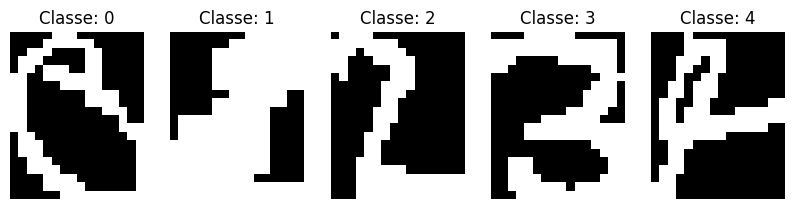

In [ ]:
# Chargement des données
caracteres_selectionnes = [0, 1, 2, 3, 4]
images, labels = lire_alpha_digit(caracteres_selectionnes)

print(f"Shape des images : {images.shape}")
print(f"Shape des labels : {labels.shape}")
print(f"Labels uniques : {np.unique(labels)}")

# Affichage des premiers caractères avec leurs classes
fig, axes = plt.subplots(1, len(caracteres_selectionnes), figsize=(10, 3))
for i, classe in enumerate(caracteres_selectionnes):
    img_index = np.where(labels == binary_alpha_labels[classe].item())[0][0]
    axes[i].imshow(images[img_index].reshape(20, 16), cmap="gray")
    axes[i].set_title(f"Classe: {binary_alpha_labels[classe].item()}")
    axes[i].axis("off")
plt.show()


Epoch 1/10000 - Reconstruction Error: 2.427024
Epoch 500/10000 - Reconstruction Error: 0.695064
Epoch 1000/10000 - Reconstruction Error: 0.443896
Epoch 1500/10000 - Reconstruction Error: 0.318841
Epoch 2000/10000 - Reconstruction Error: 0.248750
Epoch 2500/10000 - Reconstruction Error: 0.199068
Epoch 3000/10000 - Reconstruction Error: 0.165372
Epoch 3500/10000 - Reconstruction Error: 0.140862
Epoch 4000/10000 - Reconstruction Error: 0.121516
Epoch 4500/10000 - Reconstruction Error: 0.106652
Epoch 5000/10000 - Reconstruction Error: 0.093475
Epoch 5500/10000 - Reconstruction Error: 0.086303
Epoch 6000/10000 - Reconstruction Error: 0.078338
Epoch 6500/10000 - Reconstruction Error: 0.070616
Epoch 7000/10000 - Reconstruction Error: 0.064278
Epoch 7500/10000 - Reconstruction Error: 0.059241
Epoch 8000/10000 - Reconstruction Error: 0.055833
Epoch 8500/10000 - Reconstruction Error: 0.053117
Epoch 9000/10000 - Reconstruction Error: 0.049357
Epoch 9500/10000 - Reconstruction Error: 0.046277
Epoc

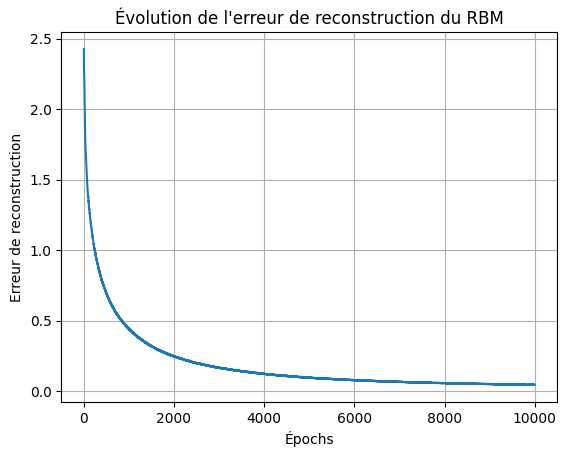

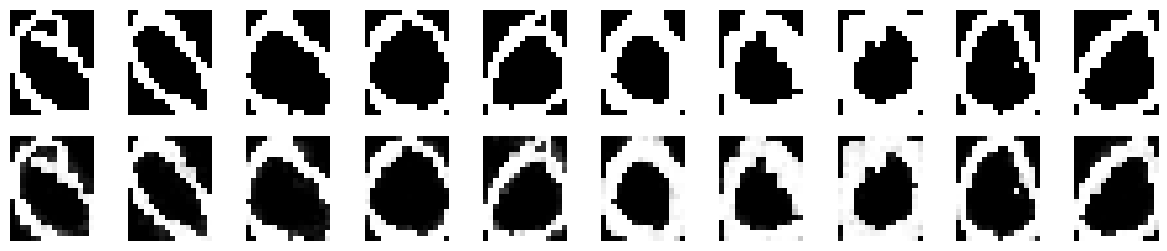

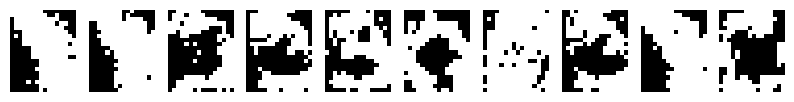

In [ ]:
# Entraînement et de la génération d’images
rbm = init_RBM(n_visible=320, n_hidden=params["taille_reseau"][1])
rbm_trained, reconstruction_errors = train_RBM(rbm, images,
                                               epochs=params["epochs"],
                                               learning_rate=params["learning_rate"],
                                               batch_size=params["batch_size"])

# Affichage de la courbe d'évolution de l'erreur de reconstruction
plt.plot(range(1, params["epochs"] + 1), reconstruction_errors)
plt.xlabel("Épochs")
plt.ylabel("Erreur de reconstruction")
plt.title("Évolution de l'erreur de reconstruction du RBM")
plt.grid()
plt.show()

# Reconstruction d'échantillons à partir du RBM entraîné
reconstructions = sortie_entree_RBM(rbm_trained, entree_sortie_RBM(rbm_trained, images[:10]))

# Affichage des images originales vs reconstruites
fig, axes = plt.subplots(2, 10, figsize=(15, 3))
for i in range(10):
    axes[0, i].imshow(images[i].reshape(20, 16), cmap="gray")
    axes[1, i].imshow(reconstructions[i].reshape(20, 16), cmap="gray")
    axes[0, i].axis("off")
    axes[1, i].axis("off")
plt.show()

# Génération de nouvelles images à partir du RBM entraîné
images_generees_rbm = generer_image_RBM(rbm_trained, n_samples=10, n_iter=5000)

Les images reconstruites conservent la structure des caractères d’origine, tandis que les échantillons générés sont plus flous, indiquant que le RBM a appris des motifs globaux mais manque encore de précision dans la génération.


Entraînement du RBM 1/2

Epoch 1/10000 - Reconstruction Error: 2.387790
Epoch 500/10000 - Reconstruction Error: 0.398468
Epoch 1000/10000 - Reconstruction Error: 0.149644
Epoch 1500/10000 - Reconstruction Error: 0.070667
Epoch 2000/10000 - Reconstruction Error: 0.041010
Epoch 2500/10000 - Reconstruction Error: 0.025675
Epoch 3000/10000 - Reconstruction Error: 0.018099
Epoch 3500/10000 - Reconstruction Error: 0.014513
Epoch 4000/10000 - Reconstruction Error: 0.011400
Epoch 4500/10000 - Reconstruction Error: 0.009214
Epoch 5000/10000 - Reconstruction Error: 0.007515
Epoch 5500/10000 - Reconstruction Error: 0.006706
Epoch 6000/10000 - Reconstruction Error: 0.005836
Epoch 6500/10000 - Reconstruction Error: 0.005426
Epoch 7000/10000 - Reconstruction Error: 0.004749
Epoch 7500/10000 - Reconstruction Error: 0.004368
Epoch 8000/10000 - Reconstruction Error: 0.004135
Epoch 8500/10000 - Reconstruction Error: 0.003671
Epoch 9000/10000 - Reconstruction Error: 0.003536
Epoch 9500/10000 - Reconstru

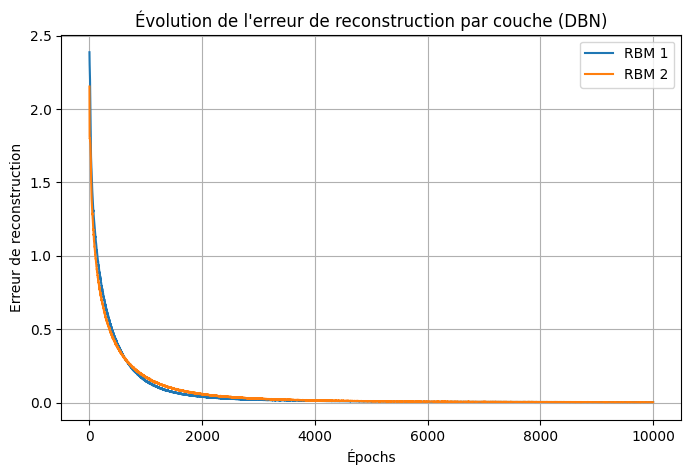

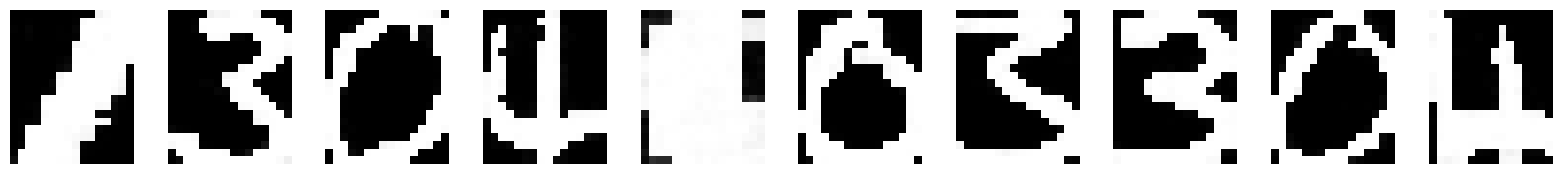

In [ ]:
# Définition de l'architecture du DBN
taille_couches = [320, 250, 150]
dbn = init_DBN(taille_couches)

# Entraînement couche par couche avec suivi des erreurs
erreurs_reconstruction_dbn = []
for i, rbm in enumerate(dbn):
    print(f"\nEntraînement du RBM {i + 1}/{len(dbn)}\n")
    dbn[i], erreurs = train_RBM(rbm, images, epochs=params["epochs"], learning_rate=params["learning_rate"], batch_size=params["batch_size"])
    erreurs_reconstruction_dbn.append(erreurs)
    images = entree_sortie_RBM(dbn[i], images)

# Affichage de l'évolution de l'erreur de reconstruction par couche
plt.figure(figsize=(8, 5))
for i, erreurs in enumerate(erreurs_reconstruction_dbn):
    plt.plot(range(1, params["epochs"] + 1), erreurs, label=f"RBM {i+1}")
plt.xlabel("Épochs")
plt.ylabel("Erreur de reconstruction")
plt.title("Évolution de l'erreur de reconstruction par couche (DBN)")
plt.legend()
plt.grid()
plt.show()

# Génération de nouvelles images à partir du DBN entraîné
images_generees_dbn = generer_image_DBN(dbn, binary_alpha_images=binary_alpha_images,
                                        caracteres_selectionnes=caracteres_selectionnes,
                                        num_iterations=10000, num_images=10)

Les images régénérées sont nettes et fidèles aux caractères d’origine, confirmant un bon apprentissage.

- Unités cachées : Plus de neurones améliorent la reconstruction, mais avec un seuil d’efficacité.

- Couches cachées : Une couche supplémentaire affine les détails sans gain significatif au-delà.

- Nombre de classes : L’apprentissage reste efficace pour un petit nombre de caractères, mais se complexifie avec plus de variabilité.

Le modèle fonctionne bien sur un ensemble restreint mais nécessiterait plus de régularisation et de données pour généraliser à un alphabet complet.

## Partie 5 - Étude à réaliser sur MNIST

Finalement, après avoir validé le bon fonctionnement de nos algorithmes, nous allons nous concentrer sur l’analyse finale sur la base MNIST. Cette étude vise à comparer les performances d’un réseau de neurones profond pré-entraîné par rapport à un DNN initialisé aléatoirement.



### 5.1 Programme

Nous suivrons les étapes suivantes pour la mise en place de notre programme d'expérimentation :

Spécification des paramètres du réseau et de l'apprentissage:

Architecture du réseau : [784, 200, 200, 10] et [784, 200, 10]

Nombre d'itérations :
25 pour l'entraînement des RBM
50 pour l'algorithme de rétropropagation

Learning rate : 0.1

Taille des mini-batchs : 10

Nombre de données d'apprentissage Total: 60 000 ou 30 000

Ces valeurs ont été choisies car un entraînement avec les paramètres initiaux aurait été beaucoup trop long (plusieurs heures). Bien que cela puisse impacter légèrement les performances, cela permet d'obtenir des résultats dans un délai raisonnable.



  0%|          | 0/5 [00:00<?, ?it/s]

Architecture: [784, 10]
Epoch 1/50, Loss: 0.3611
Epoch 2/50, Loss: 0.3036
Epoch 3/50, Loss: 0.2916
Epoch 4/50, Loss: 0.2862
Epoch 5/50, Loss: 0.2819
Epoch 6/50, Loss: 0.2791
Epoch 7/50, Loss: 0.2743
Epoch 8/50, Loss: 0.2735
Epoch 9/50, Loss: 0.2719
Epoch 10/50, Loss: 0.2698
Epoch 11/50, Loss: 0.2686
Epoch 12/50, Loss: 0.2668
Epoch 13/50, Loss: 0.2659
Epoch 14/50, Loss: 0.2651
Epoch 15/50, Loss: 0.2644
Epoch 16/50, Loss: 0.2638
Epoch 17/50, Loss: 0.2618
Epoch 18/50, Loss: 0.2619
Epoch 19/50, Loss: 0.2611
Epoch 20/50, Loss: 0.2610
Epoch 21/50, Loss: 0.2600
Epoch 22/50, Loss: 0.2587
Epoch 23/50, Loss: 0.2589
Epoch 24/50, Loss: 0.2586
Epoch 25/50, Loss: 0.2577
Epoch 26/50, Loss: 0.2577
Epoch 27/50, Loss: 0.2568
Epoch 28/50, Loss: 0.2562
Epoch 29/50, Loss: 0.2562
Epoch 30/50, Loss: 0.2566
Epoch 31/50, Loss: 0.2550
Epoch 32/50, Loss: 0.2549
Epoch 33/50, Loss: 0.2550
Epoch 34/50, Loss: 0.2545
Epoch 35/50, Loss: 0.2544
Epoch 36/50, Loss: 0.2538
Epoch 37/50, Loss: 0.2545
Epoch 38/50, Loss: 0.25

 20%|██        | 1/5 [01:30<06:03, 90.85s/it]

Epoch 50/50, Loss: 0.2510
Architecture: [784, 200, 10]

Entraînement du RBM 1/1

Epoch 1/100 - Reconstruction Error: 123.356247
Epoch 1/50, Loss: 0.2188
Epoch 2/50, Loss: 0.1205
Epoch 3/50, Loss: 0.0987
Epoch 4/50, Loss: 0.0850
Epoch 5/50, Loss: 0.0753
Epoch 6/50, Loss: 0.0675
Epoch 7/50, Loss: 0.0609
Epoch 8/50, Loss: 0.0556
Epoch 9/50, Loss: 0.0507
Epoch 10/50, Loss: 0.0467
Epoch 11/50, Loss: 0.0429
Epoch 12/50, Loss: 0.0394
Epoch 13/50, Loss: 0.0365
Epoch 14/50, Loss: 0.0338
Epoch 15/50, Loss: 0.0313
Epoch 16/50, Loss: 0.0291
Epoch 17/50, Loss: 0.0270
Epoch 18/50, Loss: 0.0250
Epoch 19/50, Loss: 0.0232
Epoch 20/50, Loss: 0.0218
Epoch 21/50, Loss: 0.0204
Epoch 22/50, Loss: 0.0190
Epoch 23/50, Loss: 0.0177
Epoch 24/50, Loss: 0.0165
Epoch 25/50, Loss: 0.0156
Epoch 26/50, Loss: 0.0146
Epoch 27/50, Loss: 0.0137
Epoch 28/50, Loss: 0.0129
Epoch 29/50, Loss: 0.0122
Epoch 30/50, Loss: 0.0116
Epoch 31/50, Loss: 0.0109
Epoch 32/50, Loss: 0.0103
Epoch 33/50, Loss: 0.0098
Epoch 34/50, Loss: 0.00

 40%|████      | 2/5 [54:20<1:35:06, 1902.12s/it]

...

 60%|██████    | 3/5 [2:01:19<1:35:37, 2868.73s/it]

Architecture: [784, 200, 200, 200, 10]

Entraînement du RBM 1/3

Epoch 1/100 - Reconstruction Error: 122.656711

Entraînement du RBM 2/3

Epoch 1/100 - Reconstruction Error: 256.954845

Entraînement du RBM 3/3

Epoch 1/100 - Reconstruction Error: 211.105890
Epoch 1/50, Loss: 0.1977
Epoch 2/50, Loss: 0.1037
Epoch 3/50, Loss: 0.0829
Epoch 4/50, Loss: 0.0702
Epoch 5/50, Loss: 0.0610
Epoch 6/50, Loss: 0.0536
Epoch 7/50, Loss: 0.0477
Epoch 8/50, Loss: 0.0431
Epoch 9/50, Loss: 0.0388
Epoch 10/50, Loss: 0.0351
Epoch 11/50, Loss: 0.0320
Epoch 12/50, Loss: 0.0292
Epoch 13/50, Loss: 0.0266
Epoch 14/50, Loss: 0.0244
Epoch 15/50, Loss: 0.0224
Epoch 16/50, Loss: 0.0205
Epoch 17/50, Loss: 0.0189
Epoch 18/50, Loss: 0.0172
Epoch 19/50, Loss: 0.0159
Epoch 20/50, Loss: 0.0147
Epoch 21/50, Loss: 0.0135
Epoch 22/50, Loss: 0.0125
Epoch 23/50, Loss: 0.0116
Epoch 24/50, Loss: 0.0107
Epoch 25/50, Loss: 0.0099
Epoch 26/50, Loss: 0.0092
Epoch 27/50, Loss: 0.0086
Epoch 28/50, Loss: 0.0080
Epoch 29/50, Loss: 0.00

 80%|████████  | 4/5 [3:22:37<1:01:01, 3661.93s/it]

Architecture: [784, 200, 200, 200, 200, 10]

Entraînement du RBM 1/4

Epoch 1/100 - Reconstruction Error: 123.374569

Entraînement du RBM 2/4

Epoch 1/100 - Reconstruction Error: 258.961081

Entraînement du RBM 3/4

Epoch 1/100 - Reconstruction Error: 212.397667

Entraînement du RBM 4/4

Epoch 1/100 - Reconstruction Error: 180.986825
Epoch 1/50, Loss: 0.1936
Epoch 2/50, Loss: 0.1031
Epoch 3/50, Loss: 0.0821
Epoch 4/50, Loss: 0.0694
Epoch 5/50, Loss: 0.0603
Epoch 6/50, Loss: 0.0529
Epoch 7/50, Loss: 0.0469
Epoch 8/50, Loss: 0.0423
Epoch 9/50, Loss: 0.0381
Epoch 10/50, Loss: 0.0346
Epoch 11/50, Loss: 0.0315
Epoch 12/50, Loss: 0.0287
Epoch 13/50, Loss: 0.0262
Epoch 14/50, Loss: 0.0241
Epoch 15/50, Loss: 0.0220
Epoch 16/50, Loss: 0.0203
Epoch 17/50, Loss: 0.0186
Epoch 18/50, Loss: 0.0173
Epoch 19/50, Loss: 0.0159
Epoch 20/50, Loss: 0.0147
Epoch 21/50, Loss: 0.0137
Epoch 22/50, Loss: 0.0127
Epoch 23/50, Loss: 0.0119
Epoch 24/50, Loss: 0.0110
Epoch 25/50, Loss: 0.0103
Epoch 26/50, Loss: 0.00

100%|██████████| 5/5 [4:58:13<00:00, 3578.72s/it]


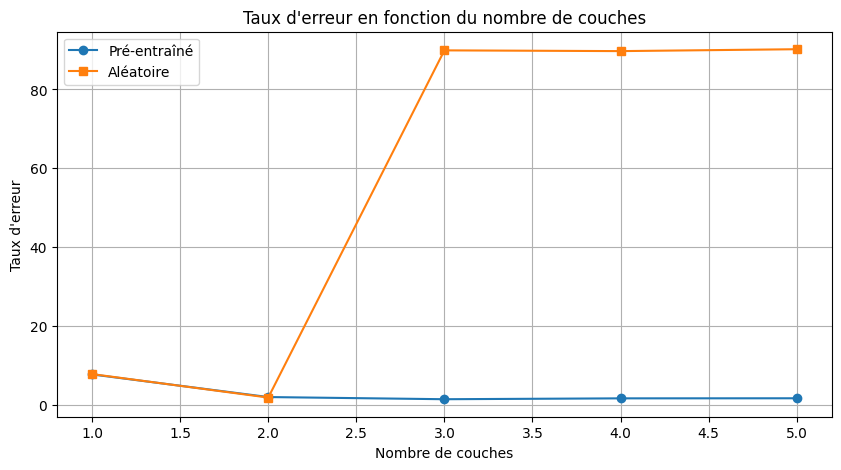

In [ ]:
def plot_results(x_values, y_pretrain, y_random, xlabel, title):
    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_pretrain, label='Pré-entraîné', marker='o')
    plt.plot(x_values, y_random, label='Aléatoire', marker='s')
    plt.xlabel(xlabel)
    plt.ylabel("Taux d'erreur")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def one_hot_encode(labels, num_classes=10):
    return np.eye(num_classes)[labels]

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"])).reshape(-1, 28 * 28) / 255.0
train_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["train_labels"])))
test_images = load_mnist_images(os.path.join(mnist_path, files["test_images"])).reshape(-1, 28 * 28) / 255.0
test_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["test_labels"])))

layers = [[784, 10], [784, 200, 10], [784, 200, 200, 10], [784, 200, 200, 200, 10], [784, 200, 200, 200, 200, 10]]
list_train, list_pretrain = [], []
rbm_epochs, bp_epochs, learning_rate, batch_size = 25, 50, 0.1, 10

for layer_sizes in tqdm(layers):
    print(f"Architecture: {layer_sizes}")
    pretrained_dnn, random_dnn = pretrain_DNN(layer_sizes, train_images), init_DNN(layer_sizes)
    pretrained_dnn = retropropagation(pretrained_dnn, train_images, train_labels, bp_epochs, learning_rate, batch_size)
    random_dnn = retropropagation(random_dnn, train_images, train_labels, bp_epochs, learning_rate, batch_size)
    list_pretrain.append(test_DNN(pretrained_dnn, test_images, test_labels))
    list_train.append(test_DNN(random_dnn, test_images, test_labels))

plot_results(range(1, len(layers)+1), list_pretrain, list_train, "Nombre de couches", "Taux d'erreur en fonction du nombre de couches")

  0%|          | 0/5 [00:00<?, ?it/s]

Nombre de neurones par couche: 100

Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 146.305385

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 436.826349
Epoch 1/50, Loss: 0.2698
Epoch 2/50, Loss: 0.1573
Epoch 3/50, Loss: 0.1287
Epoch 4/50, Loss: 0.1110
Epoch 5/50, Loss: 0.0984
Epoch 6/50, Loss: 0.0882
Epoch 7/50, Loss: 0.0802
Epoch 8/50, Loss: 0.0735
Epoch 9/50, Loss: 0.0673
Epoch 10/50, Loss: 0.0623
Epoch 11/50, Loss: 0.0578
Epoch 12/50, Loss: 0.0538
Epoch 13/50, Loss: 0.0501
Epoch 14/50, Loss: 0.0468
Epoch 15/50, Loss: 0.0438
Epoch 16/50, Loss: 0.0411
Epoch 17/50, Loss: 0.0385
Epoch 18/50, Loss: 0.0361
Epoch 19/50, Loss: 0.0339
Epoch 20/50, Loss: 0.0320
Epoch 21/50, Loss: 0.0302
Epoch 22/50, Loss: 0.0284
Epoch 23/50, Loss: 0.0268
Epoch 24/50, Loss: 0.0252
Epoch 25/50, Loss: 0.0238
Epoch 26/50, Loss: 0.0225
Epoch 27/50, Loss: 0.0213
Epoch 28/50, Loss: 0.0200
Epoch 29/50, Loss: 0.0190
Epoch 30/50, Loss: 0.0180
Epoch 31/50, Loss: 0.0171
Epoch 32/50, Loss: 0.016

 20%|██        | 1/5 [18:26<1:13:47, 1106.93s/it]

Nombre de neurones par couche: 300

Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 114.478059

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 185.152608
Epoch 1/50, Loss: 0.1855
Epoch 2/50, Loss: 0.0949
Epoch 3/50, Loss: 0.0743
Epoch 4/50, Loss: 0.0619
Epoch 5/50, Loss: 0.0533
Epoch 6/50, Loss: 0.0465
Epoch 7/50, Loss: 0.0410
Epoch 8/50, Loss: 0.0364
Epoch 9/50, Loss: 0.0324
Epoch 10/50, Loss: 0.0293
Epoch 11/50, Loss: 0.0262
Epoch 12/50, Loss: 0.0236
Epoch 13/50, Loss: 0.0214
Epoch 14/50, Loss: 0.0194
Epoch 15/50, Loss: 0.0176
Epoch 16/50, Loss: 0.0160
Epoch 17/50, Loss: 0.0146
Epoch 18/50, Loss: 0.0134
Epoch 19/50, Loss: 0.0122
Epoch 20/50, Loss: 0.0112
Epoch 21/50, Loss: 0.0104
Epoch 22/50, Loss: 0.0095
Epoch 23/50, Loss: 0.0088
Epoch 24/50, Loss: 0.0082
Epoch 25/50, Loss: 0.0076
Epoch 26/50, Loss: 0.0071
Epoch 27/50, Loss: 0.0067
Epoch 28/50, Loss: 0.0062
Epoch 29/50, Loss: 0.0058
Epoch 30/50, Loss: 0.0054
Epoch 31/50, Loss: 0.0051
Epoch 32/50, Loss: 0.004

 40%|████      | 2/5 [1:08:23<1:50:55, 2218.33s/it]

...

 60%|██████    | 3/5 [2:43:30<2:07:02, 3811.28s/it]

Nombre de neurones par couche: 700

Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 107.223047

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 85.744760
Epoch 1/50, Loss: 0.1706
Epoch 2/50, Loss: 0.0833
Epoch 3/50, Loss: 0.0646
Epoch 4/50, Loss: 0.0536
Epoch 5/50, Loss: 0.0459
Epoch 6/50, Loss: 0.0399
Epoch 7/50, Loss: 0.0352
Epoch 8/50, Loss: 0.0312
Epoch 9/50, Loss: 0.0279
Epoch 10/50, Loss: 0.0249
Epoch 11/50, Loss: 0.0222
Epoch 12/50, Loss: 0.0201
Epoch 13/50, Loss: 0.0183
Epoch 14/50, Loss: 0.0165
Epoch 15/50, Loss: 0.0150
Epoch 16/50, Loss: 0.0136
Epoch 17/50, Loss: 0.0124
Epoch 18/50, Loss: 0.0114
Epoch 19/50, Loss: 0.0104
Epoch 20/50, Loss: 0.0096
Epoch 21/50, Loss: 0.0088
Epoch 22/50, Loss: 0.0081
Epoch 23/50, Loss: 0.0075
Epoch 24/50, Loss: 0.0070
Epoch 25/50, Loss: 0.0065
Epoch 26/50, Loss: 0.0060
Epoch 27/50, Loss: 0.0056
Epoch 28/50, Loss: 0.0053
Epoch 29/50, Loss: 0.0049
Epoch 30/50, Loss: 0.0046
Epoch 31/50, Loss: 0.0044
Epoch 32/50, Loss: 0.0041

 80%|████████  | 4/5 [5:22:57<1:41:23, 6083.86s/it]

Nombre de neurones par couche: 900

Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 106.354907

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 68.198332
Epoch 1/50, Loss: 0.1691
Epoch 2/50, Loss: 0.0815
Epoch 3/50, Loss: 0.0631
Epoch 4/50, Loss: 0.0524
Epoch 5/50, Loss: 0.0447
Epoch 6/50, Loss: 0.0389
Epoch 7/50, Loss: 0.0343
Epoch 8/50, Loss: 0.0303
Epoch 9/50, Loss: 0.0272
Epoch 10/50, Loss: 0.0244
Epoch 11/50, Loss: 0.0218
Epoch 12/50, Loss: 0.0197
Epoch 13/50, Loss: 0.0178
Epoch 14/50, Loss: 0.0161
Epoch 15/50, Loss: 0.0147
Epoch 16/50, Loss: 0.0134
Epoch 17/50, Loss: 0.0122
Epoch 18/50, Loss: 0.0112
Epoch 19/50, Loss: 0.0103
Epoch 20/50, Loss: 0.0094
Epoch 21/50, Loss: 0.0087
Epoch 22/50, Loss: 0.0080
Epoch 23/50, Loss: 0.0075
Epoch 24/50, Loss: 0.0069
Epoch 25/50, Loss: 0.0065
Epoch 26/50, Loss: 0.0060
Epoch 27/50, Loss: 0.0056
Epoch 28/50, Loss: 0.0052
Epoch 29/50, Loss: 0.0049
Epoch 30/50, Loss: 0.0046
Epoch 31/50, Loss: 0.0044
Epoch 32/50, Loss: 0.0041

100%|██████████| 5/5 [9:45:05<00:00, 7021.13s/it]


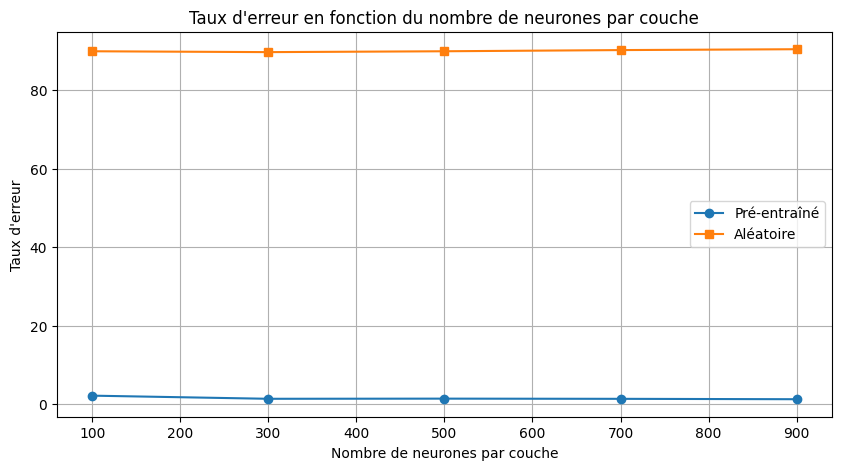

In [ ]:
def plot_results(x_values, y_pretrain, y_random, xlabel, title):
    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_pretrain, label='Pré-entraîné', marker='o')
    plt.plot(x_values, y_random, label='Aléatoire', marker='s')
    plt.xlabel(xlabel)
    plt.ylabel("Taux d'erreur")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def one_hot_encode(labels, num_classes=10):
    return np.eye(num_classes)[labels]

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"])).reshape(-1, 28 * 28) / 255.0
train_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["train_labels"])))
test_images = load_mnist_images(os.path.join(mnist_path, files["test_images"])).reshape(-1, 28 * 28) / 255.0
test_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["test_labels"])))

neurons_per_layer = [100, 300, 500, 700, 900]
list_train, list_pretrain = [], []
rbm_epochs, bp_epochs, learning_rate, batch_size = 25, 50, 0.1, 10

for n in tqdm(neurons_per_layer):
    print(f"Nombre de neurones par couche: {n}")
    layer_sizes = [784, n, n, 10]
    pretrained_dnn, random_dnn = pretrain_DNN(layer_sizes, train_images), init_DNN(layer_sizes)

    pretrained_dnn = retropropagation(pretrained_dnn, train_images, train_labels, bp_epochs, learning_rate, batch_size)
    random_dnn = retropropagation(random_dnn, train_images, train_labels, bp_epochs, learning_rate, batch_size)

    list_pretrain.append(test_DNN(pretrained_dnn, test_images, test_labels))
    list_train.append(test_DNN(random_dnn, test_images, test_labels))

plot_results(neurons_per_layer, list_pretrain, list_train, "Nombre de neurones par couche", "Taux d'erreur en fonction du nombre de neurones par couche")

  0%|          | 0/5 [00:00<?, ?it/s]

Nombre de neurones par couche: 100

Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 85.501674
Epoch 1/50, Loss: 0.3832
Epoch 2/50, Loss: 0.2397
Epoch 3/50, Loss: 0.2062
Epoch 4/50, Loss: 0.1842
Epoch 5/50, Loss: 0.1674
Epoch 6/50, Loss: 0.1539
Epoch 7/50, Loss: 0.1430
Epoch 8/50, Loss: 0.1330
Epoch 9/50, Loss: 0.1243
Epoch 10/50, Loss: 0.1167
Epoch 11/50, Loss: 0.1105
Epoch 12/50, Loss: 0.1038
Epoch 13/50, Loss: 0.0978
Epoch 14/50, Loss: 0.0933
Epoch 15/50, Loss: 0.0884
Epoch 16/50, Loss: 0.0841
Epoch 17/50, Loss: 0.0800
Epoch 18/50, Loss: 0.0759
Epoch 19/50, Loss: 0.0721
Epoch 20/50, Loss: 0.0690
Epoch 21/50, Loss: 0.0658
Epoch 22/50, Loss: 0.0627
Epoch 23/50, Loss: 0.0599
Epoch 24/50, Loss: 0.0570
Epoch 25/50, Loss: 0.0546
Epoch 26/50, Loss: 0.0521
Epoch 27/50, Loss: 0.0501
Epoch 28/50, Loss: 0.0477
Epoch 29/50, Loss: 0.0459
Epoch 30/50, Loss: 0.0441
Epoch 31/50, Loss: 0.0419
Epoch 32/50, Loss: 0.0405
Epoch 33/50, Loss: 0.0388
Epoch 34/50, Loss: 0.0373
Epoch 35/50, Loss: 

 20%|██        | 1/5 [07:30<30:02, 450.66s/it]

Nombre de neurones par couche: 300

Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 69.178002
Epoch 1/50, Loss: 0.2624
Epoch 2/50, Loss: 0.1354
Epoch 3/50, Loss: 0.1077
Epoch 4/50, Loss: 0.0911
Epoch 5/50, Loss: 0.0791
Epoch 6/50, Loss: 0.0699
Epoch 7/50, Loss: 0.0622
Epoch 8/50, Loss: 0.0556
Epoch 9/50, Loss: 0.0503
Epoch 10/50, Loss: 0.0455
Epoch 11/50, Loss: 0.0414
Epoch 12/50, Loss: 0.0377
Epoch 13/50, Loss: 0.0345
Epoch 14/50, Loss: 0.0316
Epoch 15/50, Loss: 0.0290
Epoch 16/50, Loss: 0.0266
Epoch 17/50, Loss: 0.0246
Epoch 18/50, Loss: 0.0225
Epoch 19/50, Loss: 0.0211
Epoch 20/50, Loss: 0.0195
Epoch 21/50, Loss: 0.0181
Epoch 22/50, Loss: 0.0169
Epoch 23/50, Loss: 0.0157
Epoch 24/50, Loss: 0.0146
Epoch 25/50, Loss: 0.0137
Epoch 26/50, Loss: 0.0128
Epoch 27/50, Loss: 0.0121
Epoch 28/50, Loss: 0.0113
Epoch 29/50, Loss: 0.0106
Epoch 30/50, Loss: 0.0100
Epoch 31/50, Loss: 0.0096
Epoch 32/50, Loss: 0.0090
Epoch 33/50, Loss: 0.0085
Epoch 34/50, Loss: 0.0081
Epoch 35/50, Loss: 

 40%|████      | 2/5 [24:31<39:17, 785.88s/it]

...

 60%|██████    | 3/5 [52:11<39:29, 1184.99s/it]

Nombre de neurones par couche: 700

Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 65.036097
Epoch 1/50, Loss: 0.2390
Epoch 2/50, Loss: 0.1119
Epoch 3/50, Loss: 0.0864
Epoch 4/50, Loss: 0.0713
Epoch 5/50, Loss: 0.0607
Epoch 6/50, Loss: 0.0526
Epoch 7/50, Loss: 0.0463
Epoch 8/50, Loss: 0.0408
Epoch 9/50, Loss: 0.0367
Epoch 10/50, Loss: 0.0328
Epoch 11/50, Loss: 0.0297
Epoch 12/50, Loss: 0.0268
Epoch 13/50, Loss: 0.0243
Epoch 14/50, Loss: 0.0223
Epoch 15/50, Loss: 0.0203
Epoch 16/50, Loss: 0.0185
Epoch 17/50, Loss: 0.0171
Epoch 18/50, Loss: 0.0157
Epoch 19/50, Loss: 0.0146
Epoch 20/50, Loss: 0.0135
Epoch 21/50, Loss: 0.0125
Epoch 22/50, Loss: 0.0117
Epoch 23/50, Loss: 0.0109
Epoch 24/50, Loss: 0.0102
Epoch 25/50, Loss: 0.0096
Epoch 26/50, Loss: 0.0090
Epoch 27/50, Loss: 0.0085
Epoch 28/50, Loss: 0.0081
Epoch 29/50, Loss: 0.0076
Epoch 30/50, Loss: 0.0072
Epoch 31/50, Loss: 0.0068
Epoch 32/50, Loss: 0.0065
Epoch 33/50, Loss: 0.0062
Epoch 34/50, Loss: 0.0059
Epoch 35/50, Loss: 

 80%|████████  | 4/5 [1:32:42<27:57, 1677.20s/it]

Nombre de neurones par couche: 900

Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 64.407133
Epoch 1/50, Loss: 0.2404
Epoch 2/50, Loss: 0.1126
Epoch 3/50, Loss: 0.0872
Epoch 4/50, Loss: 0.0721
Epoch 5/50, Loss: 0.0617
Epoch 6/50, Loss: 0.0538
Epoch 7/50, Loss: 0.0473
Epoch 8/50, Loss: 0.0423
Epoch 9/50, Loss: 0.0379
Epoch 10/50, Loss: 0.0340
Epoch 11/50, Loss: 0.0306
Epoch 12/50, Loss: 0.0279
Epoch 13/50, Loss: 0.0254
Epoch 14/50, Loss: 0.0232
Epoch 15/50, Loss: 0.0212
Epoch 16/50, Loss: 0.0195
Epoch 17/50, Loss: 0.0179
Epoch 18/50, Loss: 0.0165
Epoch 19/50, Loss: 0.0153
Epoch 20/50, Loss: 0.0142
Epoch 21/50, Loss: 0.0132
Epoch 22/50, Loss: 0.0122
Epoch 23/50, Loss: 0.0114
Epoch 24/50, Loss: 0.0107
Epoch 25/50, Loss: 0.0100
Epoch 26/50, Loss: 0.0094
Epoch 27/50, Loss: 0.0089
Epoch 28/50, Loss: 0.0083
Epoch 29/50, Loss: 0.0079
Epoch 30/50, Loss: 0.0075
Epoch 31/50, Loss: 0.0071
Epoch 32/50, Loss: 0.0067
Epoch 33/50, Loss: 0.0064
Epoch 34/50, Loss: 0.0061
Epoch 35/50, Loss: 

100%|██████████| 5/5 [2:26:59<00:00, 1763.96s/it]


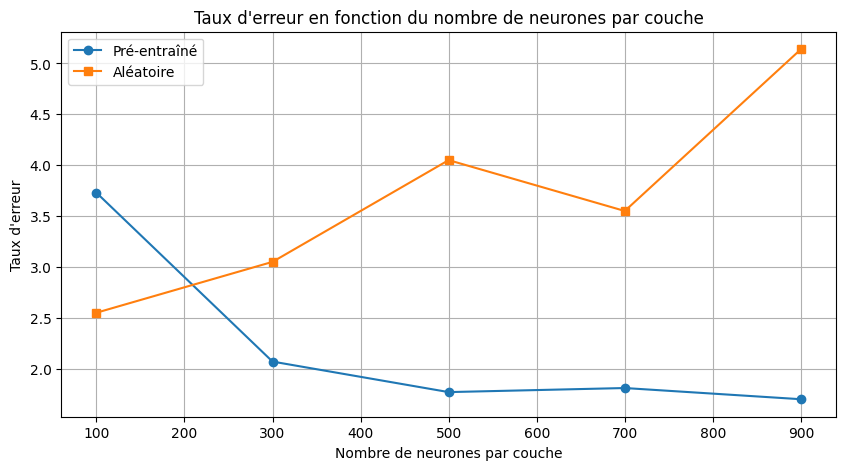

In [ ]:
def plot_results(x_values, y_pretrain, y_random, xlabel, title):
    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_pretrain, label='Pré-entraîné', marker='o')
    plt.plot(x_values, y_random, label='Aléatoire', marker='s')
    plt.xlabel(xlabel)
    plt.ylabel("Taux d'erreur")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def one_hot_encode(labels, num_classes=10):
    return np.eye(num_classes)[labels]

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"])).reshape(-1, 28 * 28) / 255.0
train_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["train_labels"])))
test_images = load_mnist_images(os.path.join(mnist_path, files["test_images"])).reshape(-1, 28 * 28) / 255.0
test_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["test_labels"])))

neurons_per_layer = [100, 300, 500, 700, 900]
list_train, list_pretrain = [], []
rbm_epochs, bp_epochs, learning_rate, batch_size = 25, 50, 0.1, 10

for n in tqdm(neurons_per_layer):
    train_subset_images, train_subset_labels = train_images[:30000], train_labels[:30000]
    print(f"Nombre de neurones par couche: {n}")
    layer_sizes = [784, n, 10]
    pretrained_dnn, random_dnn = pretrain_DNN(layer_sizes, train_subset_images), init_DNN(layer_sizes)

    pretrained_dnn = retropropagation(pretrained_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)
    random_dnn = retropropagation(random_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)

    list_pretrain.append(test_DNN(pretrained_dnn, test_images, test_labels))
    list_train.append(test_DNN(random_dnn, test_images, test_labels))

plot_results(neurons_per_layer, list_pretrain, list_train, "Nombre de neurones par couche", "Taux d'erreur en fonction du nombre de neurones par couche")

  0%|          | 0/6 [00:00<?, ?it/s]


Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 6.344926

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 13.963276
Epoch 1/50, Loss: 1.0560
Epoch 2/50, Loss: 0.5354
Epoch 3/50, Loss: 0.4320
Epoch 4/50, Loss: 0.3817
Epoch 5/50, Loss: 0.3446
Epoch 6/50, Loss: 0.3162
Epoch 7/50, Loss: 0.2941
Epoch 8/50, Loss: 0.2753
Epoch 9/50, Loss: 0.2594
Epoch 10/50, Loss: 0.2435
Epoch 11/50, Loss: 0.2297
Epoch 12/50, Loss: 0.2151
Epoch 13/50, Loss: 0.2065
Epoch 14/50, Loss: 0.1961
Epoch 15/50, Loss: 0.1851
Epoch 16/50, Loss: 0.1764
Epoch 17/50, Loss: 0.1663
Epoch 18/50, Loss: 0.1570
Epoch 19/50, Loss: 0.1503
Epoch 20/50, Loss: 0.1426
Epoch 21/50, Loss: 0.1348
Epoch 22/50, Loss: 0.1289
Epoch 23/50, Loss: 0.1229
Epoch 24/50, Loss: 0.1172
Epoch 25/50, Loss: 0.1109
Epoch 26/50, Loss: 0.1065
Epoch 27/50, Loss: 0.1012
Epoch 28/50, Loss: 0.0974
Epoch 29/50, Loss: 0.0925
Epoch 30/50, Loss: 0.0888
Epoch 31/50, Loss: 0.0845
Epoch 32/50, Loss: 0.0807
Epoch 33/50, Loss: 0.0775
Epoch 34/5

 17%|█▋        | 1/6 [00:34<02:51, 34.38s/it]


Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 14.314031

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 34.158862
Epoch 1/50, Loss: 0.6753
Epoch 2/50, Loss: 0.3354
Epoch 3/50, Loss: 0.2767
Epoch 4/50, Loss: 0.2402
Epoch 5/50, Loss: 0.2145
Epoch 6/50, Loss: 0.1959
Epoch 7/50, Loss: 0.1781
Epoch 8/50, Loss: 0.1642
Epoch 9/50, Loss: 0.1527
Epoch 10/50, Loss: 0.1399
Epoch 11/50, Loss: 0.1322
Epoch 12/50, Loss: 0.1230
Epoch 13/50, Loss: 0.1147
Epoch 14/50, Loss: 0.1075
Epoch 15/50, Loss: 0.1011
Epoch 16/50, Loss: 0.0945
Epoch 17/50, Loss: 0.0888
Epoch 18/50, Loss: 0.0838
Epoch 19/50, Loss: 0.0790
Epoch 20/50, Loss: 0.0742
Epoch 21/50, Loss: 0.0705
Epoch 22/50, Loss: 0.0665
Epoch 23/50, Loss: 0.0629
Epoch 24/50, Loss: 0.0599
Epoch 25/50, Loss: 0.0570
Epoch 26/50, Loss: 0.0537
Epoch 27/50, Loss: 0.0513
Epoch 28/50, Loss: 0.0483
Epoch 29/50, Loss: 0.0463
Epoch 30/50, Loss: 0.0442
Epoch 31/50, Loss: 0.0420
Epoch 32/50, Loss: 0.0401
Epoch 33/50, Loss: 0.0384
Epoch 34/

 33%|███▎      | 2/6 [02:12<04:47, 71.79s/it]

...

 67%|██████▋   | 4/6 [11:36<07:17, 218.72s/it]


Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 74.025336

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 168.310724
Epoch 1/50, Loss: 0.2725
Epoch 2/50, Loss: 0.1442
Epoch 3/50, Loss: 0.1150
Epoch 4/50, Loss: 0.0977
Epoch 5/50, Loss: 0.0848
Epoch 6/50, Loss: 0.0749
Epoch 7/50, Loss: 0.0671
Epoch 8/50, Loss: 0.0604
Epoch 9/50, Loss: 0.0548
Epoch 10/50, Loss: 0.0498
Epoch 11/50, Loss: 0.0453
Epoch 12/50, Loss: 0.0416
Epoch 13/50, Loss: 0.0382
Epoch 14/50, Loss: 0.0350
Epoch 15/50, Loss: 0.0322
Epoch 16/50, Loss: 0.0298
Epoch 17/50, Loss: 0.0274
Epoch 18/50, Loss: 0.0253
Epoch 19/50, Loss: 0.0235
Epoch 20/50, Loss: 0.0218
Epoch 21/50, Loss: 0.0203
Epoch 22/50, Loss: 0.0187
Epoch 23/50, Loss: 0.0175
Epoch 24/50, Loss: 0.0163
Epoch 25/50, Loss: 0.0152
Epoch 26/50, Loss: 0.0142
Epoch 27/50, Loss: 0.0132
Epoch 28/50, Loss: 0.0123
Epoch 29/50, Loss: 0.0116
Epoch 30/50, Loss: 0.0109
Epoch 31/50, Loss: 0.0102
Epoch 32/50, Loss: 0.0097
Epoch 33/50, Loss: 0.0091
Epoch 34

 83%|████████▎ | 5/6 [28:03<08:15, 495.57s/it]


Entraînement du RBM 1/2

Epoch 1/25 - Reconstruction Error: 123.213599

Entraînement du RBM 2/2

Epoch 1/25 - Reconstruction Error: 259.336212
Epoch 1/50, Loss: 0.2115
Epoch 2/50, Loss: 0.1132
Epoch 3/50, Loss: 0.0897
Epoch 4/50, Loss: 0.0754
Epoch 5/50, Loss: 0.0651
Epoch 6/50, Loss: 0.0573
Epoch 7/50, Loss: 0.0507
Epoch 8/50, Loss: 0.0454
Epoch 9/50, Loss: 0.0409
Epoch 10/50, Loss: 0.0368
Epoch 11/50, Loss: 0.0333
Epoch 12/50, Loss: 0.0302
Epoch 13/50, Loss: 0.0274
Epoch 14/50, Loss: 0.0250
Epoch 15/50, Loss: 0.0228
Epoch 16/50, Loss: 0.0208
Epoch 17/50, Loss: 0.0190
Epoch 18/50, Loss: 0.0174
Epoch 19/50, Loss: 0.0159
Epoch 20/50, Loss: 0.0147
Epoch 21/50, Loss: 0.0135
Epoch 22/50, Loss: 0.0125
Epoch 23/50, Loss: 0.0115
Epoch 24/50, Loss: 0.0106
Epoch 25/50, Loss: 0.0099
Epoch 26/50, Loss: 0.0092
Epoch 27/50, Loss: 0.0085
Epoch 28/50, Loss: 0.0080
Epoch 29/50, Loss: 0.0075
Epoch 30/50, Loss: 0.0070
Epoch 31/50, Loss: 0.0066
Epoch 32/50, Loss: 0.0062
Epoch 33/50, Loss: 0.0058
Epoch 3

100%|██████████| 6/6 [1:00:50<00:00, 608.47s/it]


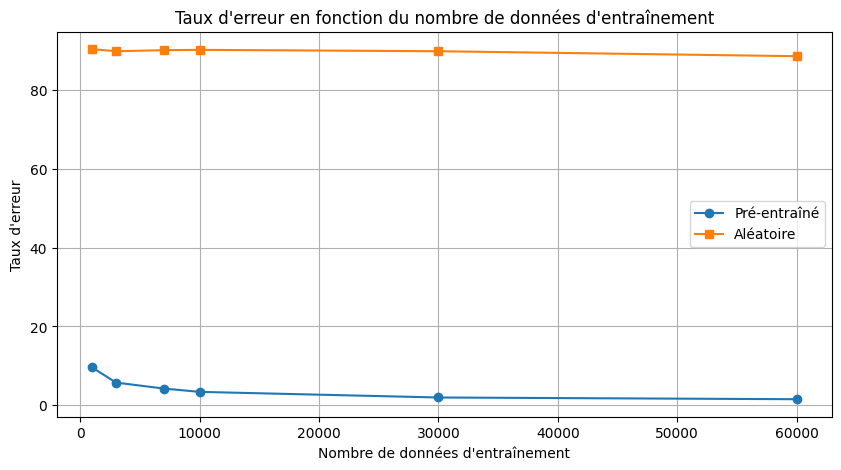

In [ ]:
def plot_results(x_values, y_pretrain, y_random, xlabel, title):
    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_pretrain, label='Pré-entraîné', marker='o')
    plt.plot(x_values, y_random, label='Aléatoire', marker='s')
    plt.xlabel(xlabel)
    plt.ylabel("Taux d'erreur")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def one_hot_encode(labels, num_classes=10):
    return np.eye(num_classes)[labels]

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"])).reshape(-1, 28 * 28) / 255.0
train_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["train_labels"])))
test_images = load_mnist_images(os.path.join(mnist_path, files["test_images"])).reshape(-1, 28 * 28) / 255.0
test_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["test_labels"])))

train_sizes = [1000, 3000, 7000, 10000, 30000, 60000]
list_train, list_pretrain = [], []
rbm_epochs, bp_epochs, learning_rate, batch_size = 25, 50, 0.1, 10

for n in tqdm(train_sizes):
    train_subset_images, train_subset_labels = train_images[:n], train_labels[:n]
    layer_sizes = [784, 200, 200, 10]
    pretrained_dnn, random_dnn = pretrain_DNN(layer_sizes, train_subset_images), init_DNN(layer_sizes)

    pretrained_dnn = retropropagation(pretrained_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)
    random_dnn = retropropagation(random_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)

    list_pretrain.append(test_DNN(pretrained_dnn, test_images, test_labels))
    list_train.append(test_DNN(random_dnn, test_images, test_labels))

plot_results(train_sizes, list_pretrain, list_train, "Nombre de données d'entraînement", "Taux d'erreur en fonction du nombre de données d'entraînement")

  0%|          | 0/6 [00:00<?, ?it/s]


Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 6.391617
Epoch 1/50, Loss: 1.0711
Epoch 2/50, Loss: 0.5179
Epoch 3/50, Loss: 0.4051
Epoch 4/50, Loss: 0.3443
Epoch 5/50, Loss: 0.3060
Epoch 6/50, Loss: 0.2777
Epoch 7/50, Loss: 0.2547
Epoch 8/50, Loss: 0.2362
Epoch 9/50, Loss: 0.2184
Epoch 10/50, Loss: 0.2036
Epoch 11/50, Loss: 0.1903
Epoch 12/50, Loss: 0.1784
Epoch 13/50, Loss: 0.1669
Epoch 14/50, Loss: 0.1583
Epoch 15/50, Loss: 0.1497
Epoch 16/50, Loss: 0.1431
Epoch 17/50, Loss: 0.1344
Epoch 18/50, Loss: 0.1282
Epoch 19/50, Loss: 0.1210
Epoch 20/50, Loss: 0.1153
Epoch 21/50, Loss: 0.1090
Epoch 22/50, Loss: 0.1044
Epoch 23/50, Loss: 0.0985
Epoch 24/50, Loss: 0.0942
Epoch 25/50, Loss: 0.0895
Epoch 26/50, Loss: 0.0855
Epoch 27/50, Loss: 0.0816
Epoch 28/50, Loss: 0.0776
Epoch 29/50, Loss: 0.0743
Epoch 30/50, Loss: 0.0712
Epoch 31/50, Loss: 0.0680
Epoch 32/50, Loss: 0.0649
Epoch 33/50, Loss: 0.0623
Epoch 34/50, Loss: 0.0603
Epoch 35/50, Loss: 0.0577
Epoch 36/50, Loss: 0.0553
Epo

 17%|█▋        | 1/6 [00:25<02:08, 25.62s/it]


Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 14.301994
Epoch 1/50, Loss: 0.7172
Epoch 2/50, Loss: 0.3561
Epoch 3/50, Loss: 0.2862
Epoch 4/50, Loss: 0.2476
Epoch 5/50, Loss: 0.2188
Epoch 6/50, Loss: 0.1978
Epoch 7/50, Loss: 0.1802
Epoch 8/50, Loss: 0.1636
Epoch 9/50, Loss: 0.1521
Epoch 10/50, Loss: 0.1406
Epoch 11/50, Loss: 0.1308
Epoch 12/50, Loss: 0.1212
Epoch 13/50, Loss: 0.1139
Epoch 14/50, Loss: 0.1055
Epoch 15/50, Loss: 0.0989
Epoch 16/50, Loss: 0.0925
Epoch 17/50, Loss: 0.0869
Epoch 18/50, Loss: 0.0814
Epoch 19/50, Loss: 0.0770
Epoch 20/50, Loss: 0.0716
Epoch 21/50, Loss: 0.0678
Epoch 22/50, Loss: 0.0636
Epoch 23/50, Loss: 0.0601
Epoch 24/50, Loss: 0.0570
Epoch 25/50, Loss: 0.0535
Epoch 26/50, Loss: 0.0507
Epoch 27/50, Loss: 0.0486
Epoch 28/50, Loss: 0.0460
Epoch 29/50, Loss: 0.0437
Epoch 30/50, Loss: 0.0415
Epoch 31/50, Loss: 0.0397
Epoch 32/50, Loss: 0.0380
Epoch 33/50, Loss: 0.0362
Epoch 34/50, Loss: 0.0347
Epoch 35/50, Loss: 0.0332
Epoch 36/50, Loss: 0.0320
Ep

 33%|███▎      | 2/6 [01:55<04:12, 63.21s/it]

...

 67%|██████▋   | 4/6 [09:37<05:57, 178.62s/it]


Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 73.944432
Epoch 1/50, Loss: 0.3016
Epoch 2/50, Loss: 0.1702
Epoch 3/50, Loss: 0.1391
Epoch 4/50, Loss: 0.1196
Epoch 5/50, Loss: 0.1058
Epoch 6/50, Loss: 0.0945
Epoch 7/50, Loss: 0.0853
Epoch 8/50, Loss: 0.0776
Epoch 9/50, Loss: 0.0706
Epoch 10/50, Loss: 0.0650
Epoch 11/50, Loss: 0.0596
Epoch 12/50, Loss: 0.0549
Epoch 13/50, Loss: 0.0506
Epoch 14/50, Loss: 0.0467
Epoch 15/50, Loss: 0.0432
Epoch 16/50, Loss: 0.0403
Epoch 17/50, Loss: 0.0372
Epoch 18/50, Loss: 0.0344
Epoch 19/50, Loss: 0.0321
Epoch 20/50, Loss: 0.0299
Epoch 21/50, Loss: 0.0279
Epoch 22/50, Loss: 0.0259
Epoch 23/50, Loss: 0.0243
Epoch 24/50, Loss: 0.0227
Epoch 25/50, Loss: 0.0213
Epoch 26/50, Loss: 0.0199
Epoch 27/50, Loss: 0.0188
Epoch 28/50, Loss: 0.0176
Epoch 29/50, Loss: 0.0166
Epoch 30/50, Loss: 0.0156
Epoch 31/50, Loss: 0.0148
Epoch 32/50, Loss: 0.0139
Epoch 33/50, Loss: 0.0132
Epoch 34/50, Loss: 0.0126
Epoch 35/50, Loss: 0.0119
Epoch 36/50, Loss: 0.0113
Ep

 83%|████████▎ | 5/6 [22:04<06:23, 383.66s/it]


Entraînement du RBM 1/1

Epoch 1/25 - Reconstruction Error: 123.414625
Epoch 1/50, Loss: 0.2252
Epoch 2/50, Loss: 0.1260
Epoch 3/50, Loss: 0.1026
Epoch 4/50, Loss: 0.0880
Epoch 5/50, Loss: 0.0776
Epoch 6/50, Loss: 0.0691
Epoch 7/50, Loss: 0.0621
Epoch 8/50, Loss: 0.0565
Epoch 9/50, Loss: 0.0515
Epoch 10/50, Loss: 0.0470
Epoch 11/50, Loss: 0.0431
Epoch 12/50, Loss: 0.0395
Epoch 13/50, Loss: 0.0365
Epoch 14/50, Loss: 0.0337
Epoch 15/50, Loss: 0.0311
Epoch 16/50, Loss: 0.0287
Epoch 17/50, Loss: 0.0267
Epoch 18/50, Loss: 0.0248
Epoch 19/50, Loss: 0.0229
Epoch 20/50, Loss: 0.0212
Epoch 21/50, Loss: 0.0198
Epoch 22/50, Loss: 0.0184
Epoch 23/50, Loss: 0.0172
Epoch 24/50, Loss: 0.0161
Epoch 25/50, Loss: 0.0151
Epoch 26/50, Loss: 0.0140
Epoch 27/50, Loss: 0.0131
Epoch 28/50, Loss: 0.0124
Epoch 29/50, Loss: 0.0116
Epoch 30/50, Loss: 0.0110
Epoch 31/50, Loss: 0.0103
Epoch 32/50, Loss: 0.0098
Epoch 33/50, Loss: 0.0092
Epoch 34/50, Loss: 0.0087
Epoch 35/50, Loss: 0.0083
Epoch 36/50, Loss: 0.0079
E

100%|██████████| 6/6 [46:45<00:00, 467.56s/it]


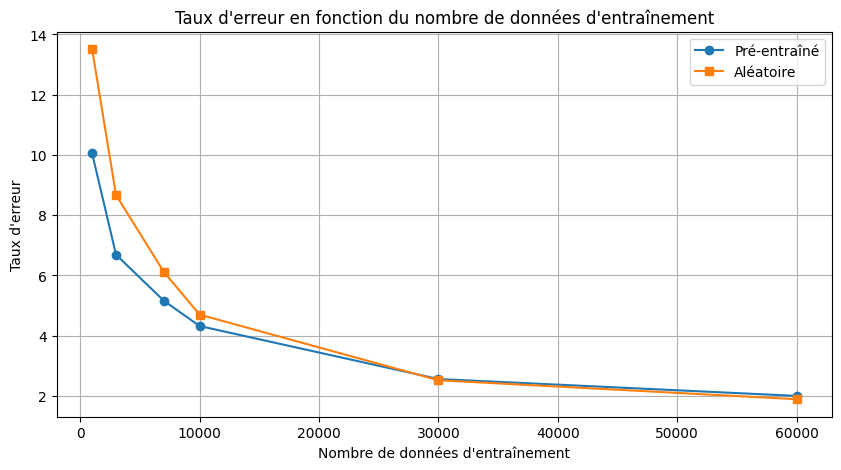

In [ ]:
def plot_results(x_values, y_pretrain, y_random, xlabel, title):
    plt.figure(figsize=(10, 5))
    plt.plot(x_values, y_pretrain, label='Pré-entraîné', marker='o')
    plt.plot(x_values, y_random, label='Aléatoire', marker='s')
    plt.xlabel(xlabel)
    plt.ylabel("Taux d'erreur")
    plt.title(title)
    plt.legend()
    plt.grid()
    plt.show()

mnist_path = "./"
files = {"train_images": "train-images-idx3-ubyte.gz", "train_labels": "train-labels-idx1-ubyte.gz",
         "test_images": "t10k-images-idx3-ubyte.gz", "test_labels": "t10k-labels-idx1-ubyte.gz"}

def one_hot_encode(labels, num_classes=10):
    return np.eye(num_classes)[labels]

train_images = load_mnist_images(os.path.join(mnist_path, files["train_images"])).reshape(-1, 28 * 28) / 255.0
train_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["train_labels"])))
test_images = load_mnist_images(os.path.join(mnist_path, files["test_images"])).reshape(-1, 28 * 28) / 255.0
test_labels = one_hot_encode(load_mnist_labels(os.path.join(mnist_path, files["test_labels"])))

train_sizes = [1000, 3000, 7000, 10000, 30000, 60000]
list_train, list_pretrain = [], []
rbm_epochs, bp_epochs, learning_rate, batch_size = 25, 50, 0.1, 10

for n in tqdm(train_sizes):
    train_subset_images, train_subset_labels = train_images[:n], train_labels[:n]
    layer_sizes = [784, 200, 10]
    pretrained_dnn, random_dnn = pretrain_DNN(layer_sizes, train_subset_images), init_DNN(layer_sizes)

    pretrained_dnn = retropropagation(pretrained_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)
    random_dnn = retropropagation(random_dnn, train_subset_images, train_subset_labels, bp_epochs, learning_rate, batch_size)

    list_pretrain.append(test_DNN(pretrained_dnn, test_images, test_labels))
    list_train.append(test_DNN(random_dnn, test_images, test_labels))

plot_results(train_sizes, list_pretrain, list_train, "Nombre de données d'entraînement", "Taux d'erreur en fonction du nombre de données d'entraînement")

5.2 Analyse

Nous allons comparer les performances d'un réseau de neurones pré-entraîné avec un réseau initialisé aléatoirement en réalisant trois types d'analyses distinctes. L'objectif est d'observer l'impact de plusieurs paramètres sur la capacité du modèle à généraliser et sur son efficacité en termes de convergence.

1. Impact du nombre de couches sur les performances:

Nous avons fait varier le nombre de couches tout en gardant le même nombre de neurones par couche.
Nous pouvons clairement voir que pour le meilleur résultat pour le réseau aléatoire est obtenu à 1 couches (784 -> 200 -> 10) et que les résultats se dégradent énormément après, probablement en raison des difficultés d'optimisation et de la propagation du gradient. Par contre pour le réseau pré-entraîné, l'augmentation du nombre de couches a un impact moindre sur la performance, bien que les gains deviennent marginaux après un certain seuil.  tandis que le temps de calcul grandit énormément.

2. Impact du nombre de neurones par couche:

Nous avons mené cette analyse en testant deux architectures différentes : 2 couches cachées avec un nombre variable de neurones et 1 couche cachée avec un nombre variable de neurones.

Expérience avec 2 couches cachées:

Nous avons testé des architectures avec 100, 300, 500, 700 et 900 neurones par couche. Le réseau pré-entraîné affiche systématiquement de meilleures performances que le réseau initialisé aléatoirement. Lorsque le nombre de neurones augmente, le taux d'erreur du modèle pré-entraîné diminue jusqu'à un certain seuil, après quoi il se stabilise, avec le meilleur résultat autour de 300 neurones. En revanche, pour le modèle aléatoire, on observe un taux d'erreur stable mais élevée, ce qui suggère un surajustement ou des difficultés d'apprentissage pour des architectures trop complexes sans pré-entraînement, ce qui correspond aux résultats de l'expérience précédente.

Expérience avec 1 couche cachée:

Nous avons testé des architectures avec 100, 300, 500, 700 et 900 neurones. Dans cette configuration, les performances sont nettement meilleures qu'avec deux couches cachées. Le réseau pré-entraîné obtient des taux d'erreur plus bas pour chaque configuration, avec le meilleur résultat à 900 neurones. Le modèle aléatoire s'améliore également, avec un minimum globale lorsque nous avons 100 neurones, et plus il y a de neurones, moins le score est bon avec un minimum local à 700 neurones.

3. Impact du nombre de données d'apprentissage:

Nous avons de nouveau testé deux architectures : 2 couches cachées de 200 neurones et 1 couche cachée de 200 neurones.

Expérience avec deux couches cachées:

Le taux d'erreur diminue logiquement avec l'augmentation du nombre de données d'apprentissage. Le modèle pré-entraîné affiche des performances largement meilleures que le modèle aléatoire, surtout pour des petits jeux de données.Les performances des deux modèles ne convergent pas.

Expérience avec une seule couche cachée:

Avec cette architecture, les performances sont globalement meilleures. Le modèle pré-entraîné atteint un taux d'erreur plus faible, même avec peu de données. Le modèle aléatoire, bien que moins performant au début, donne un bien meilleur résultat que dans le cas à deux couches cachées. Les deux modèles convergent lorsqu'il y a plus de 30000 données.

Ainsi, la meilleure architecture pour obtenir des performances optimales sur un modèle pré-entraîné est composée de 2 couches cachées avec une architecture 784 -> 300 -> 300 -> 10. Cette configuration donne les meilleurs résultats. Pour un modèle aléatoire, la meilleure configuration est plutôt 1 couche cachée avec une architecture 784 -> 100 -> 10. Dans les deux modèles un grand nombre (<30000) de données d'entraînement est idéal.
